In [15]:
import pandas as pd
from sklearn.preprocessing import StandardScaler

raw_df = pd.read_csv('comportamiento_jugadores.csv')
display(raw_df)

economia_juego = raw_df[raw_df['Escenario'] == '1_Economia_Juego']
deteccion_hackers = raw_df[raw_df['Escenario'] == '2_Deteccion_Hackers']
estilos_batalla = raw_df[raw_df['Escenario'] == '3_Estilos_Batalla']

X_crudo_economia_juego = economia_juego[['Metrica_X', 'Metrica_Y']]
X_escalado_economia_juego = StandardScaler().fit_transform(X_crudo_economia_juego)

X_crudo_deteccion_hackers = deteccion_hackers[['Metrica_X', 'Metrica_Y']]
X_escalado_deteccion_hackers = StandardScaler().fit_transform(X_crudo_deteccion_hackers)

X_crudo_estilos_batalla = estilos_batalla[['Metrica_X', 'Metrica_Y']]
X_escalado_estilos_batalla = StandardScaler().fit_transform(X_crudo_estilos_batalla)

,Metrica_X,Metrica_Y,Escenario,Descripcion_Ejes
0,44.125085,74.436148,1_Economia_Juego,X: Horas_Semana | Y: Gasto_USD
1,19.905609,115.313604,1_Economia_Juego,X: Horas_Semana | Y: Gasto_USD
2,55.833550,119.616643,1_Economia_Juego,X: Horas_Semana | Y: Gasto_USD
3,10.243052,129.259511,1_Economia_Juego,X: Horas_Semana | Y: Gasto_USD
4,5.413660,259.896958,1_Economia_Juego,X: Horas_Semana | Y: Gasto_USD
...,...,...,...,...
1795,2270.067519,72.707213,3_Estilos_Batalla,X: Distancia_Metros | Y: Cajas_Loot_Abiertas
1796,1003.790472,64.590489,3_Estilos_Batalla,X: Distancia_Metros | Y: Cajas_Loot_Abiertas
1797,3309.609429,23.893436,3_Estilos_Batalla,X: Distancia_Metros | Y: Cajas_Loot_Abiertas
1798,1650.694480,44.669431,3_Estilos_Batalla,X: Distancia_Metros | Y: Cajas_Loot_Abiertas


### **Paso 1: Carga, Segmentación y Escalado de Datos**

En esta primera etapa del proyecto, preparamos nuestros datos para que el modelo de Inteligencia Artificial pueda procesarlos de manera correcta. El proceso consta de tres subpasos:

1. Importación de Librerías y Carga de Datos:
   - Usamos pandas para leer `comportamiento_jugadores.csv`.

2. Segmentación por Escenarios:
   - El conjunto de datos original contiene registros de jugadores en distintas situaciones del juego. Filtramos la tabla original en tres escenarios independientes:
     - Economía del Juego
     - Detección de Hackers
     - Estilos de Batalla.

3. Selección de Características y Escalado:
  - Extraemos las columnas clave: `Metrica_X` y `Metrica_Y`.
  - Despues se realiza un re-escalado para no tener que trabajar con rangos que no tienen comparación, como 0 a 10 y 0 a 10,000, asi estandarizando los valores sin ningun desnivel

In [ ]:
%pip install numpy

from sklearn.cluster import SpectralClustering
import numpy as np
from sklearn.metrics import silhouette_score

X = X_escalado_estilos_batalla

cl = []

for i in range(2 ,12):
  clustering = SpectralClustering(n_clusters=i,
        assign_labels='discretize',
        random_state=0).fit_predict(X)
  cl.append(clustering)

for i in range(len(cl)):
 print(f"{i} : {silhouette_score(X, cl[i])}")


labels_to_plot = cl[7]
print(labels_to_plot)
#clustering

0 : 0.374956600053777
1 : 0.39457464169182205
2 : 0.47218009070104955
3 : 0.5133033224671258
4 : 0.5268191168012766
5 : 0.5247324008502653
6 : 0.5257176371088129
7 : 0.5264020759557542
8 : 0.5251664731704725
9 : 0.4242949596417671
[1 0 0 6 7 3 3 0 6 0 6 1 1 0 0 5 2 5 7 1 3 0 0 0 0 0 6 8 0 0 0 7 6 4 7 0 8
 0 0 3 0 2 0 0 2 7 0 1 6 0 4 4 1 0 0 0 5 7 8 5 6 7 0 0 0 6 0 0 6 0 0 3 0 0
 0 0 0 4 0 0 3 0 0 0 6 2 8 5 0 5 4 0 6 0 4 3 5 3 0 6 1 5 0 0 6 0 8 3 4 0 5
 0 0 0 0 0 0 8 0 0 8 3 0 0 7 8 0 3 0 0 1 0 7 8 0 5 6 1 3 6 2 5 8 6 0 1 0 0
 2 3 0 0 0 0 0 4 2 0 1 1 0 5 2 0 0 8 3 3 0 0 4 3 0 0 7 6 0 2 1 4 1 3 0 0 0
 0 0 0 0 4 0 0 6 5 0 3 0 0 0 8 8 0 0 7 5 3 4 3 4 0 0 0 0 1 5 8 0 3 0 2 7 0
 6 0 0 0 0 0 6 0 2 0 5 0 0 6 0 4 0 3 0 0 0 8 8 0 0 0 7 2 1 2 7 0 6 6 0 5 2
 3 4 0 0 7 0 0 3 1 7 0 0 0 3 2 0 0 0 2 2 0 0 3 0 0 0 0 0 5 2 0 4 6 5 2 8 4
 0 7 0 0 7 0 0 0 6 0 7 0 8 7 8 0 0 0 0 1 0 6 0 0 1 0 0 0 5 0 0 0 0 3 0 2 8
 4 0 0 6 1 0 0 4 0 3 8 4 0 0 2 0 0 7 0 8 0 0 8 0 0 0 0 8 0 1 8 4 0 1 0 3 3
 0 1 7 7 0 4 0 0 0 

### **Paso 2: Evaluación del Número de Clusters y Visualización**

En esta etapa, evaluamos cuál es la mejor configuración para agrupar nuestros datos y creamos una representación visual para entender el comportamiento de los jugadores:

1. Prueba de Múltiples Agrupaciones:
   - Ejecutamos el algoritmo de Spectral Clustering variando la cantidad de grupos desde 2 hasta 11.
   - Guardamos cada resultado en una lista para poder compararlos.

2. Evaluación de Calidad (Silhouette Score):
   - Calculamos la métrica de silueta para cada experimento. Esta métrica mide qué tan bien definidos y separados quedaron los grupos.
   - Identificamos que la configuración de 9 clusters (posición `cl[7]`) ofrece uno de los mejores resultados de separación.

3. Visualización Gráfica:
   - Graficamos los puntos en un plano bidimensional utilizando las métricas escaladas.
   - Pintamos cada punto según el grupo asignado utilizando una paleta de colores contrastantes.
   - Añadimos una barra de colores para mapear visualmente cada color con su respectivo identificador de cluster (del 0 al 8).

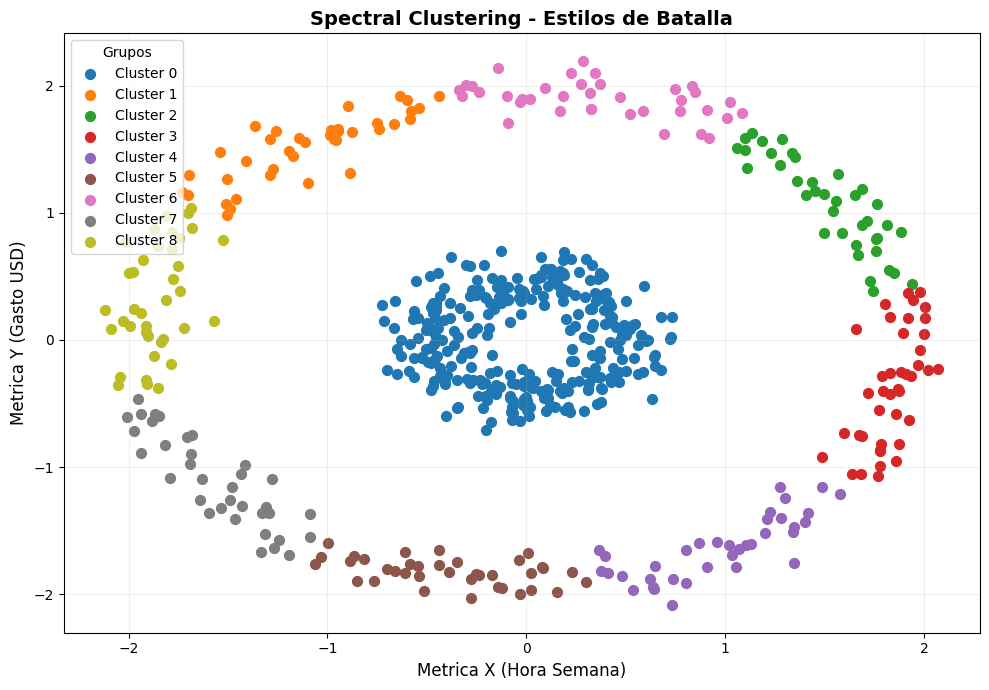

In [17]:
import matplotlib.pyplot as plt
import numpy as np

#labels
X = X_escalado_estilos_batalla
labels_to_plot = np.array(cl[7])

#grafica
plt.figure(figsize=(10, 7))

for c in np.unique(labels_to_plot):
    plt.scatter(
        X[labels_to_plot == c, 0],
        X[labels_to_plot == c, 1],
        s=50,
        label=f'Cluster {c}'
    )

plt.title('Spectral Clustering - Estilos de Batalla',
          fontsize=14, fontweight='bold')

plt.xlabel('Metrica X (Hora Semana)', fontsize=12)
plt.ylabel('Metrica Y (Gasto USD)', fontsize=12)

#leyenda
plt.legend(title='Grupos')

plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

In [18]:
X = X_escalado_economia_juego

cl = []

for i in range(2 ,12):
  clustering = SpectralClustering(n_clusters=i,
        assign_labels='discretize',
        random_state=0).fit_predict(X)
  cl.append(clustering)

for i in range(len(cl)):
 print(f"{i} : {silhouette_score(X, cl[i])}")


labels_to_plot_economia = cl[1]
print(labels_to_plot_economia)
#clustering

0 : 0.67829569856441
1 : 0.7376041101300008
2 : 0.5421633345204365
3 : 0.44811790701112403
4 : 0.3326775291673212
5 : 0.2712275975521306
6 : 0.3197294036901288
7 : 0.32568143871993527
8 : 0.3292270931563552
9 : 0.3126201452695786
[2 1 2 1 0 0 2 0 2 2 0 0 1 1 0 0 2 1 0 2 0 1 2 0 1 0 2 2 2 2 2 2 0 0 0 1 0
 0 1 0 0 0 2 2 2 1 0 1 0 2 2 1 1 0 2 0 2 0 0 2 0 2 2 1 0 2 0 1 1 1 0 2 2 2
 1 1 2 1 1 1 2 0 2 2 1 1 2 1 1 1 0 1 1 0 0 2 2 1 1 0 2 0 0 1 0 1 2 0 2 2 1
 1 0 0 1 1 2 1 0 1 0 0 0 1 1 0 2 1 2 2 0 1 0 2 0 2 1 0 2 2 0 1 0 0 0 1 1 1
 1 0 2 0 2 1 1 1 2 1 1 0 0 0 0 1 0 2 0 1 0 0 0 1 1 0 2 1 1 2 2 1 0 0 1 1 0
 2 0 1 2 2 1 1 0 0 1 0 2 2 2 2 1 2 0 0 1 1 1 0 1 2 2 0 2 2 1 1 0 2 0 1 0 2
 2 0 0 1 1 1 2 0 0 1 0 0 2 2 2 1 2 0 0 2 0 2 0 1 0 1 1 0 2 2 0 1 0 1 2 0 2
 2 0 1 2 1 2 2 0 0 2 0 2 2 0 2 2 1 0 2 2 2 0 2 0 0 2 2 0 2 1 2 2 2 2 2 2 1
 2 0 0 2 1 0 0 0 0 0 0 1 0 1 2 2 2 2 1 2 0 0 0 1 2 1 2 1 1 2 0 1 2 1 0 1 1
 2 0 0 2 0 2 1 1 2 2 1 0 0 0 2 1 1 0 1 1 0 0 1 0 2 1 0 2 2 2 2 1 2 0 0 2 2
 0 2 0 1 2 1 0 2 1 0

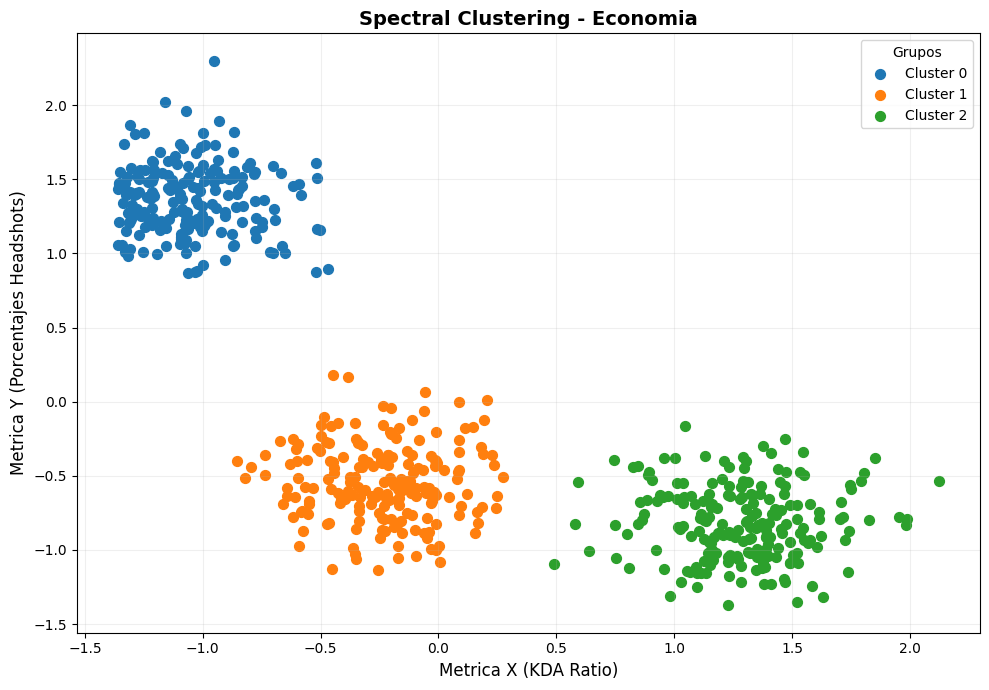

In [19]:
#labels
X = X_escalado_economia_juego
labels_to_plot = np.array(cl[1])

#grafica
plt.figure(figsize=(10, 7))

for c in np.unique(labels_to_plot):
    plt.scatter(
        X[labels_to_plot == c, 0],
        X[labels_to_plot == c, 1],
        s=50,
        label=f'Cluster {c}'
    )

plt.title('Spectral Clustering - Economia',
          fontsize=14, fontweight='bold')

plt.xlabel('Metrica X (KDA Ratio)', fontsize=12)
plt.ylabel('Metrica Y (Porcentajes Headshots)', fontsize=12)

#leyenda
plt.legend(title='Grupos')

plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

In [31]:
X = X_escalado_deteccion_hackers

cl = []

for i in range(2 ,12):
  clustering = SpectralClustering(n_clusters=i,
        assign_labels='discretize',affinity='nearest_neighbors',n_neighbors=40,
        random_state=0).fit_predict(X)
  cl.append(clustering)

for i in range(len(cl)):
 print(f"{i} : {silhouette_score(X, cl[i])}")


labels_to_plot_hackers = cl[0]
print(labels_to_plot_hackers)
#clustering

0 : 0.39706242593853824
1 : 0.3450643506180942
2 : 0.3949442489325958
3 : 0.42677091878334616
4 : 0.4857434105434584
5 : 0.48914988999966774
6 : 0.49467023419300377
7 : 0.5042314607192451
8 : 0.5009522379710426
9 : 0.4901047275297795
[1 0 0 1 1 1 1 0 1 0 1 1 1 0 0 1 1 1 1 1 1 0 0 0 0 0 1 1 0 0 0 1 1 1 1 0 1
 0 0 1 0 1 0 0 1 1 0 1 1 0 1 1 1 0 0 0 1 1 1 1 1 1 0 0 0 1 0 0 1 0 0 1 0 0
 0 0 0 1 0 0 1 0 0 0 1 1 1 1 0 1 1 0 1 1 1 1 1 1 0 1 1 1 0 0 1 0 1 1 1 0 1
 0 0 0 0 0 0 1 0 0 1 1 0 0 1 1 0 1 0 0 1 0 1 1 0 1 1 1 1 1 1 1 1 1 0 1 0 0
 1 1 0 0 0 0 0 1 1 0 1 1 0 1 1 0 0 1 1 1 0 0 1 1 0 0 1 1 0 1 1 1 1 1 0 0 0
 0 0 0 0 1 0 0 1 1 0 1 0 0 0 1 1 0 0 1 1 1 1 1 1 0 0 0 0 1 1 1 0 1 0 1 1 0
 1 1 0 0 0 0 1 0 1 0 1 0 0 1 0 1 0 1 0 0 0 1 1 0 0 0 1 1 1 1 1 0 1 1 0 1 1
 1 1 0 0 1 0 0 1 1 1 0 0 0 1 1 0 0 0 1 1 0 0 1 0 0 0 0 0 1 1 0 1 1 1 1 1 1
 0 1 0 0 1 0 0 0 1 0 1 0 1 1 1 0 0 0 0 1 0 1 0 0 1 0 0 0 1 0 0 0 0 1 0 1 1
 1 1 0 1 1 0 0 1 0 1 1 1 0 0 1 0 0 1 0 1 0 0 1 0 0 0 0 1 0 1 1 1 0 1 0 1 1
 0 1 1 1 0 1 0 0

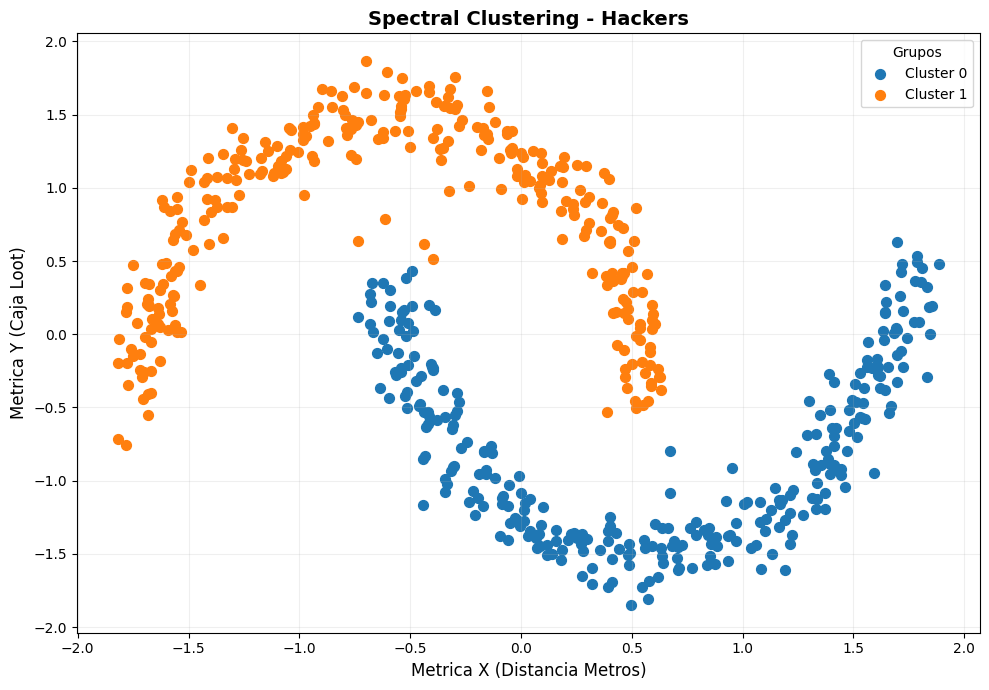

In [32]:
#labels
X = X_escalado_deteccion_hackers
labels_to_plot = np.array(cl[0])

#grafica
plt.figure(figsize=(10, 7))

for c in np.unique(labels_to_plot):
    plt.scatter(
        X[labels_to_plot == c, 0],
        X[labels_to_plot == c, 1],
        s=50,
        label=f'Cluster {c}'
    )

plt.title('Spectral Clustering - Hackers',
          fontsize=14, fontweight='bold')

plt.xlabel('Metrica X (Distancia Metros)', fontsize=12)
plt.ylabel('Metrica Y (Caja Loot)', fontsize=12)

#leyenda
plt.legend(title='Grupos')

plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()